<a href="https://colab.research.google.com/github/fouazkhechine/tPdm/blob/main/tp.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

# Load dataset
train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

# Remove missing values
train_df = train_df.dropna(subset=["sentence", "sentiment"]).copy()
test_df = test_df.dropna(subset=["sentence", "sentiment"]).copy()

# Prepare text and labels
X = train_df["sentence"].astype(str)
y = train_df["sentiment"].astype(int)

X_test = test_df["sentence"].astype(str)
y_test = test_df["sentiment"].astype(int)

print("Train:", X.shape)
print("Test:", X_test.shape)
print("\nLabel distribution:")
print(y.value_counts())
print("\nTest labels:")
print(y_test.value_counts())

Train: (1523975,)
Test: (359,)

Label distribution:
sentiment
0    767059
1    756916
Name: count, dtype: int64

Test labels:
sentiment
1    182
0    177
Name: count, dtype: int64


In [12]:
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.10,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Test samples:", len(X_test))

Training samples: 1371577
Validation samples: 152398
Test samples: 359


In [13]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

MAX_WORDS = 30000
MAX_LEN = 40

tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)

# Fit only on training data to avoid data leakage
tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_val_seq = tokenizer.texts_to_sequences(X_val)
X_test_seq = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(
    X_train_seq, maxlen=MAX_LEN, padding="post", truncating="post"
)

X_val_pad = pad_sequences(
    X_val_seq, maxlen=MAX_LEN, padding="post", truncating="post"
)

X_test_pad = pad_sequences(
    X_test_seq, maxlen=MAX_LEN, padding="post", truncating="post"
)

vocab_size = min(MAX_WORDS, len(tokenizer.word_index) + 1)

print("Vocabulary size:", vocab_size)
print("Training shape:", X_train_pad.shape)
print("Validation shape:", X_val_pad.shape)
print("Test shape:", X_test_pad.shape)

Vocabulary size: 30000
Training shape: (1371577, 40)
Validation shape: (152398, 40)
Test shape: (359, 40)


In [14]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding, LSTM, Bidirectional, Dropout, Dense
)
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(42)

model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=128,
        mask_zero=True
    ),
    Bidirectional(LSTM(64)),
    Dropout(0.5),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [16]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

MAX_LEN = 40

X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_val_pad = pad_sequences(
    X_val_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

print(X_train_pad[:3])

[[   4 1079   17    4 1672   10  151 1602   10    5  612   39 1117   53
     4 1463 2525    0    0    0    0    0    0    0    0    0    0    0
     0    0    0    0    0    0    0    0    0    0    0    0]
 [   2   80    2   21  268    3 3810  109    0    0    0    0    0    0
     0    0    0    0    0    0    0    0    0    0    0    0    0    0
     0    0    0    0    0    0    0    0    0    0    0    0]
 [  73    1  977   36   10    4   78  593  218 1356   18    7   40    4
    78 3179 6217   19   90 1228   19  315    1    0    0    0    0    0
     0    0    0    0    0    0    0    0    0    0    0    0]]


In [17]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding, LSTM, Bidirectional, Dropout, Dense
)

tf.keras.backend.clear_session()

model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=128,
        mask_zero=True
    ),
    Bidirectional(
        LSTM(64)
    ),
    Dropout(0.5),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [20]:
from tensorflow.keras.callbacks import EarlyStopping
import time

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

start_time = time.time()

history = model.fit(
    X_train_pad,
    y_train,
    validation_data=(X_val_pad, y_val),
    epochs=5,
    batch_size=256,
    callbacks=[early_stopping],
    verbose=1
)

print(f"Training time: {(time.time() - start_time) / 60:.2f} minutes")

Epoch 1/5
5358/5358 ━━━━━━━━━━━━━━━━━━━━ 804s 149ms/step - accuracy: 0.8061 - loss: 0.4219 - val_accuracy: 0.8192 - val_loss: 0.3964
Epoch 2/5
5358/5358 ━━━━━━━━━━━━━━━━━━━━ 830s 155ms/step - accuracy: 0.8318 - loss: 0.3756 - val_accuracy: 0.8230 - val_loss: 0.3926
Epoch 3/5
5358/5358 ━━━━━━━━━━━━━━━━━━━━ 822s 153ms/step - accuracy: 0.8480 - loss: 0.3450 - val_accuracy: 0.8191 - val_loss: 0.4102
Epoch 4/5
5358/5358 ━━━━━━━━━━━━━━━━━━━━ 818s 153ms/step - accuracy: 0.8653 - loss: 0.3110 - val_accuracy: 0.8141 - val_loss: 0.4550
Training time: 54.57 minutes


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
Test Accuracy : 0.8105849582172702
Test Precision: 0.796875
Test Recall   : 0.8406593406593407
Test F1-score : 0.8181818181818182

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.78      0.80       177
           1       0.80      0.84      0.82       182

    accuracy                           0.81       359
   macro avg       0.81      0.81      0.81       359
weighted avg       0.81      0.81      0.81       359



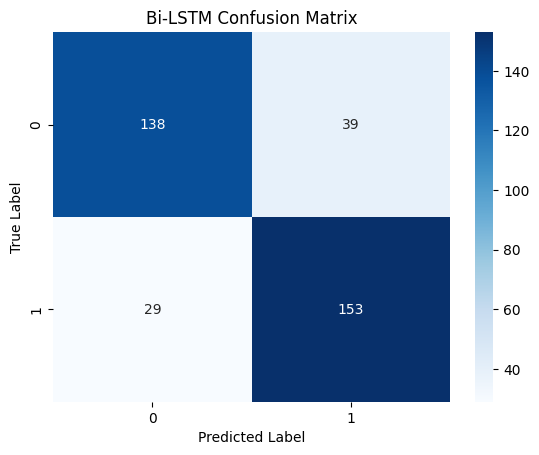

In [23]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import seaborn as sns
import matplotlib.pyplot as plt

# Predict probabilities
y_prob = model.predict(X_test_pad, batch_size=256).ravel()

# Convert probabilities to binary predictions
y_pred = (y_prob >= 0.5).astype(int)

print("Test Accuracy :", accuracy_score(y_test, y_pred))
print("Test Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Test Recall   :", recall_score(y_test, y_pred, zero_division=0))
print("Test F1-score :", f1_score(y_test, y_pred, zero_division=0))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Bi-LSTM Confusion Matrix")
plt.show()

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
              precision    recall  f1-score   support

           0       0.82      0.87      0.84       177
           1       0.87      0.81      0.84       182

    accuracy                           0.84       359
   macro avg       0.84      0.84      0.84       359
weighted avg       0.84      0.84      0.84       359



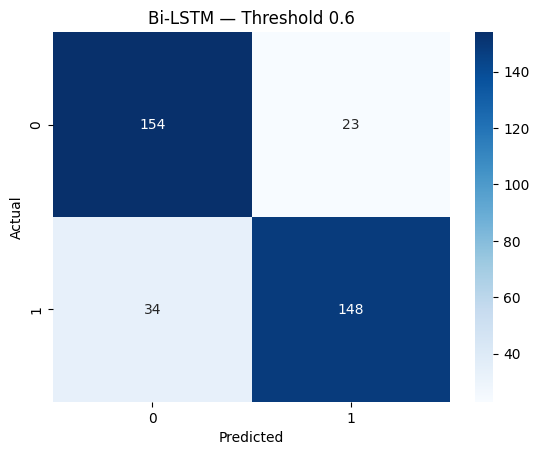

In [22]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

best_threshold = 0.60  # Replace with the threshold selected on validation data

y_prob = model.predict(X_test_pad, batch_size=256).ravel()
y_pred = (y_prob >= best_threshold).astype(int)

print(classification_report(y_test, y_pred, zero_division=0))

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Bi-LSTM — Threshold {best_threshold}")
plt.show()